# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Índice
1. **Carga del conjunto de datos.**
2. **Inspección y análisis del conjunto de datos.**
3. **Acondicionamiento y preprocesamiento de los datos.**
4. **Estrategia 1: entrenamiento desde cero (*from scratch*).**

    4.1. Diseño de la arquitectura y entrenamiento del modelo.

    4.2. Monitorización del entrenamiento y toma de decisiones.

    4.3. Evaluación del modelo y análisis de los resultados.

5. **Estrategia 2: redes preentrenadas (*transfer learning* y *fine-tuning*).**

   5.1. Diseño de la arquitectura y entrenamiento del modelo.

   5.2. Monitorización del entrenamiento y toma de decisiones.

   5.3. Evaluación del modelo y análisis de los resultados.
   
6. **Comparación de las estrategias y conclusiones.**

## 1. Carga del conjunto de datos

Desde Kaggle, obtenemos el dataset Stanford Dogs para clasificación. Para descargarlo usamos `kagglehub` que descarga y descomprime el dataset automáticamente. 

In [3]:
import kagglehub

path = kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset")
print("Path to dataset files:", path)

c:\Users\usuario\miniconda3\envs\redes\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\usuario\.cache\kagglehub\datasets\jessicali9530\stanford-dogs-dataset\versions\2


En la sección 3 del índice se implementará una función reutilizable que automatice la descarga, acondicionamiento y preprocesamiento del conjunto de datos. 

## 2. Inspección y análisis del conjunto de datos

Primeramente, fijar la semilla para reproducibilidad y librerías en esta sección.

In [10]:
import random
import numpy as np
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

import os
import matplotlib.pyplot as plt
import cv2
from PIL import Image

Para justificar la elección del dataset de imágenes para clasificación, describimos las características principales del dataset.  Una vez descargado, vemos cómo están organizados los archivos. Se tienen dos carpetas `annotations` y `images`. La carpeta `images` contiene una subcarpeta por cada raza de perro. En total hay 120 razas de perro.

In [4]:
print(os.listdir(path))

['annotations', 'images']


In [5]:
img_dir_path = os.path.join(path, "images")
print(os.listdir(img_dir_path))

['Images']


In [6]:
img_dir = os.path.join(img_dir_path, "Images")
print(os.listdir(img_dir)[:5])
total_razas = sorted(os.listdir(img_dir))
print("Número de carpetas:", len(total_razas))

['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
Número de carpetas: 120


Al acceder al contenido de una carpeta, una raza, vemos que se encuentran las imágenes de cada una en formato `.jpg`. A continuación, una muestra de las imágenes de varias razas.  

['n02085620_10074.jpg', 'n02085620_10131.jpg', 'n02085620_10621.jpg', 'n02085620_1073.jpg', 'n02085620_10976.jpg']


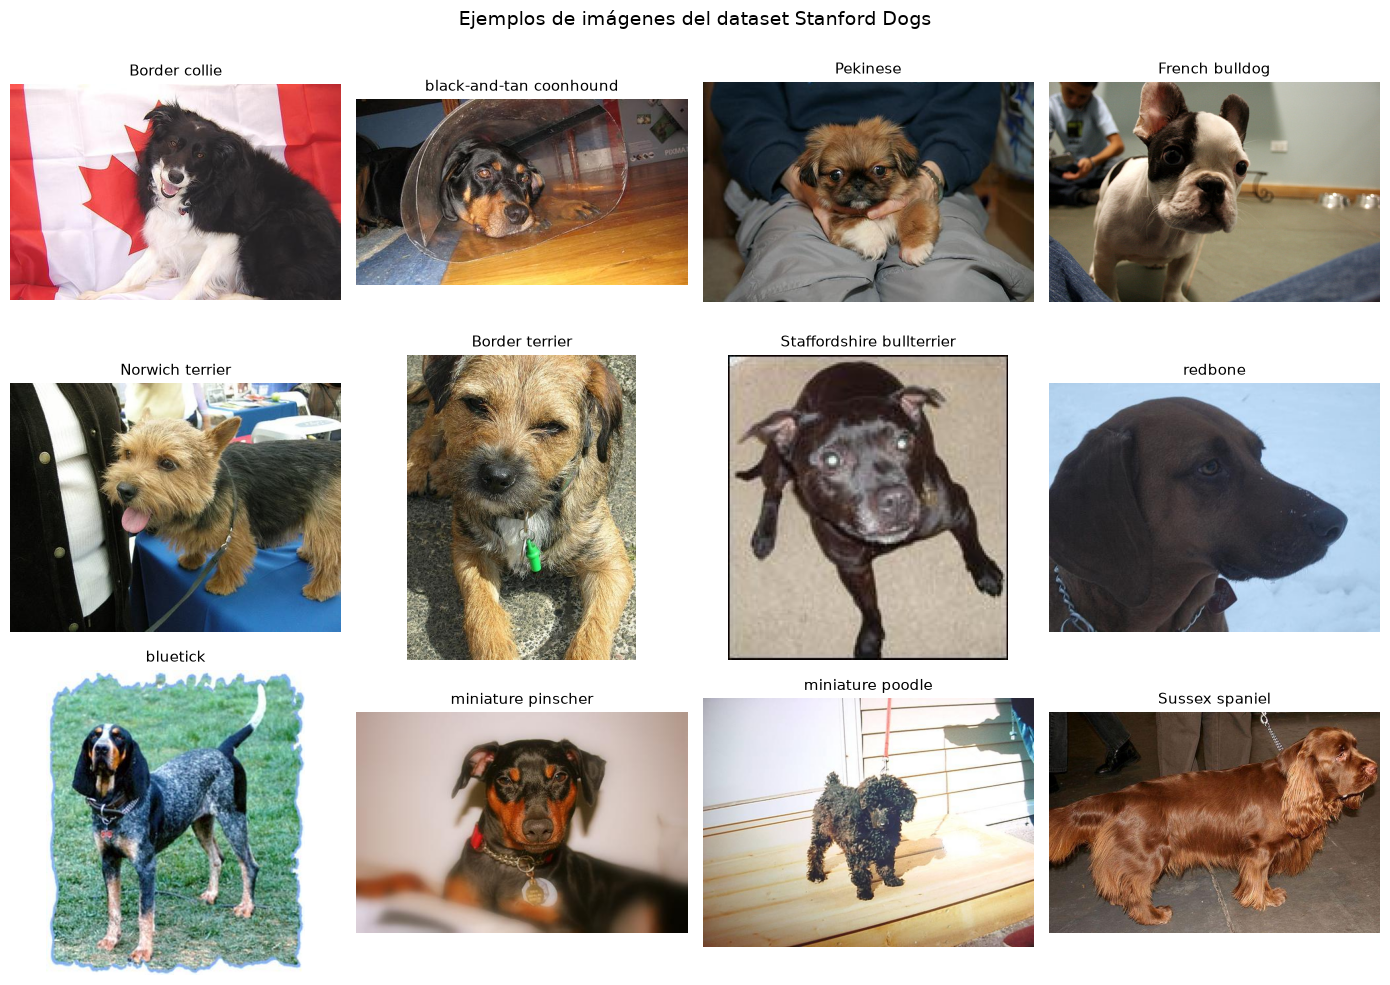

In [22]:
print(os.listdir(os.path.join(img_dir, "n02085620-Chihuahua"))[:5])

random.seed(SEED)
razas_muestra = random.sample(total_razas, 12)   # 12 razas distintas al azar

def nombre_raza(ruta):
    """De '.../n02085620-Chihuahua/foto.jpg' a 'Chihuahua'."""
    return os.path.basename(os.path.dirname(ruta)).split("-", 1)[1].replace("_", " ")

def mostrar_cuadricula(rutas_img, titulos, titulo_general, filas=3, columnas=4):
    fig, axes = plt.subplots(filas, columnas, figsize=(14, 10))
    for ax, ruta, titulo in zip(axes.flat, rutas_img, titulos):
        ax.imshow(Image.open(ruta))
        ax.set_title(titulo, fontsize=11)
        ax.axis("off")
    plt.suptitle(titulo_general, fontsize=14)
    plt.tight_layout()
    plt.show()

rutas_img = [os.path.join(img_dir, c, random.choice(os.listdir(os.path.join(img_dir, c))))
             for c in razas_muestra]

mostrar_cuadricula(rutas_img, [nombre_raza(r) for r in rutas_img],
                   "Ejemplos de imágenes del dataset Stanford Dogs")

Veamos cuántas imágenes hay en cada carpeta por raza, es decir, por clase. Con ello también se obtiene el número total de imágenes del dataset, el mínimo número de imágenes por raza, el máximo y la media. Representamos la distribución de las clases en un gráfico de barras ordenado de mayor a menor, con una línea horizontal en la media y así comprobar si el dataset está equilibrado.

Número total de imágenes: 20580
Imágenes por raza con mínimo: 148 , máximo: 252 , media: 171.5


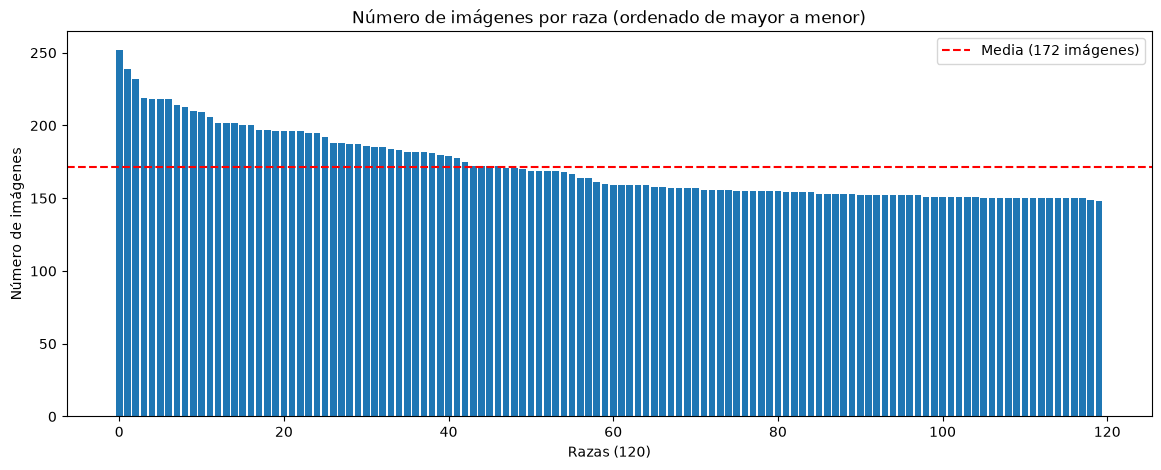

In [13]:
conteo_por_raza = []
for r in total_razas:
    a = len(os.listdir(os.path.join(img_dir, r)))
    conteo_por_raza.append(a)
total_imagenes = sum(conteo_por_raza)
media = total_imagenes / len(total_razas)
print("Número total de imágenes:", total_imagenes)
print("Imágenes por raza con mínimo:", min(conteo_por_raza), ", máximo:", max(conteo_por_raza), ", media:", media)
conteo_ordenado = sorted(conteo_por_raza, reverse=True)

plt.figure(figsize=(14, 5))
plt.bar(range(len(conteo_ordenado)), conteo_ordenado)
plt.axhline(media, color="red", linestyle="--", label=f"Media ({media:.0f} imágenes)")
plt.title("Número de imágenes por raza (ordenado de mayor a menor)")
plt.xlabel("Razas (120)")
plt.ylabel("Número de imágenes")
plt.legend()
plt.show()

El número de imágenes por raza va de 148 a 252, con una media de unas 171. Aunque la clase más grande tiene unas 252/148 $\approx$ 1,7 veces más imágenes que la más pequeña, ninguna raza está claramente infrarrepresentada, así que el dataset está razonablemente equilibrado. Por eso usaremos la accuracy como métrica principal, sin ponderar las clases.

Esto también nos da una referencia mínima para los modelos. Un clasificador aleatorio acertaría 1/120 $\approx$ 0,8 % de las veces, y un clasificador trivial que siempre predijera la raza más frecuente acertaría 252/20580 $\approx$ 1,2 %. Cualquier modelo que haya aprendido algo de los datos debe superar estos valores.

Vemos también las dimensiones de las imágenes. Para ello leemos el ancho y el alto de cada una (con PIL) y los representamos en un mapa de calor, donde las zonas más intensas indican los tamaños más frecuentes.

Hay 4542 tamaños distintos
Ancho: mínimo 97 , máximo 3264 , mediana 500
Alto:  mínimo 100 , máximo 2562 , mediana 375
Tamaño más frecuente: 500x375 (5301 imágenes, 25.8% del total)
Tamaños distintos en Chihuahua: 81


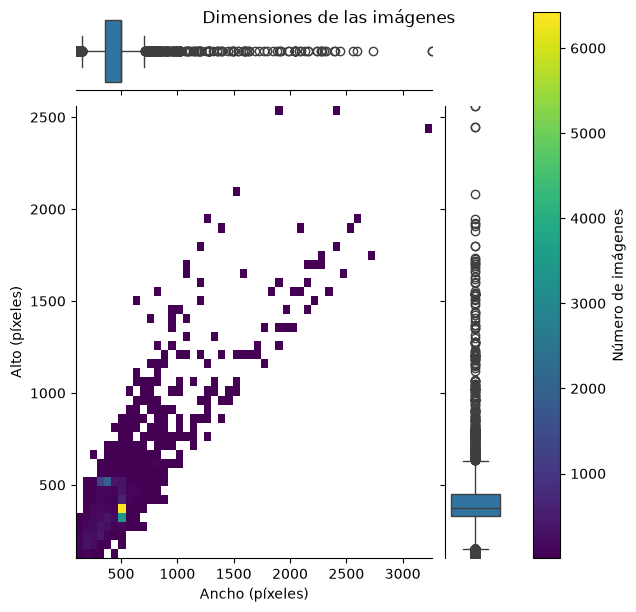

In [33]:
from glob import glob
from collections import Counter
from PIL import Image
import seaborn as sns

rutas = glob(os.path.join(img_dir, "*", "*.jpg"))
tamanos = [Image.open(r).size for r in rutas]
anchos, altos = zip(*tamanos)
tamanos_distintos = Counter(tamanos)

(w, h), n = tamanos_distintos.most_common(1)[0]

print("Hay", len(tamanos_distintos), "tamaños distintos")
print("Ancho: mínimo", min(anchos), ", máximo", max(anchos), ", mediana", int(np.median(anchos)))
print("Alto:  mínimo", min(altos),  ", máximo", max(altos),  ", mediana", int(np.median(altos)))
print(f"Tamaño más frecuente: {w}x{h} ({n} imágenes, {n / len(tamanos):.1%} del total)")

chihuahua = Counter(t for r, t in zip(rutas, tamanos) if "Chihuahua" in r)
print("Tamaños distintos en Chihuahua:", len(chihuahua))

g = sns.JointGrid(x=np.array(anchos), y=np.array(altos), height=6)
mapa = g.ax_joint.hist2d(anchos, altos, bins=50, cmap="viridis", cmin=1)
g.plot_marginals(sns.boxplot)

# Barra de color para toda la figura
g.figure.colorbar(mapa[3], ax=[g.ax_joint, g.ax_marg_x, g.ax_marg_y], label="Número de imágenes")

g.set_axis_labels("Ancho (píxeles)", "Alto (píxeles)")
g.figure.suptitle("Dimensiones de las imágenes")
plt.show()

Las imágenes no tienen un tamaño uniforme, hay 4542 tamaños distintos. Los píxeles del ancho van de 97 a 3264 píxeles y del alto de 100 a 2562, y la mayoría se concentra en torno a 500x375. Hay tamaños distintos incluso dentro de la misma raza, como por ejemplo 81 en Chihuahua. Como una red convolucional necesita que todas las entradas tengan el mismo tamaño, en el preprocesamiento redimensionaremos todas las imágenes a un tamaño fijo. Elegiremos 224x224 para la Estrategia 1, que es el tamaño de entrada estándar de las redes preentrenadas en ImageNet que usaremos en la Estrategia 2. De esta forma será posible comparar en igualdad de condiciones la Estrategia 1 y 2.

Por último, la carpeta `annotations` del dataset contiene una subcarpeta `Annotation`, organizada igual que `images`, es decir, con una carpeta por raza. Dentro de cada una hay un archivo por foto, con el mismo nombre que la imagen pero sin la extensión `.jpg`.

In [36]:
ann_dir_path = os.path.join(path, "annotations")
print(os.listdir(ann_dir_path))
ann_dir = os.path.join(ann_dir_path, "Annotation")
print(os.listdir(ann_dir)[:5])
print(os.listdir(os.path.join(ann_dir, "n02085620-Chihuahua"))[:5])

['Annotation']
['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
['n02085620_10074', 'n02085620_10131', 'n02085620_10621', 'n02085620_1073', 'n02085620_10976']


Al abrir uno de ellos (`n02085620_10074`, de la carpeta Chihuahua) vemos que es un archivo de texto con información sobre la foto con el nombre de la raza del perro, el tamaño de la imagen y una caja (`bndbox`) que marca dónde aparece el perro dentro de la foto.

Esta información sería útil para un problema de detección, pero nosotros solo queremos clasificar la raza, así que trabajaremos únicamente con las imágenes. Además, vemos que las fotos provienen de **ImageNet**, por lo que lo tendremos en cuenta más adelante al usar redes preentrenadas, ya que se entrenaron con ese mismo conjunto de datos.

In [42]:
with open(os.path.join(ann_dir, "n02085620-Chihuahua", "n02085620_10074")) as f:
    print(f.read())

<annotation>
	<folder>02085620</folder>
	<filename>n02085620_10074</filename>
	<source>
		<database>ImageNet database</database>
	</source>
	<size>
		<width>333</width>
		<height>500</height>
		<depth>3</depth>
	</size>
	<segment>0</segment>
	<object>
		<name>Chihuahua</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>25</xmin>
			<ymin>10</ymin>
			<xmax>276</xmax>
			<ymax>498</ymax>
		</bndbox>
	</object>
</annotation>


## 3. Acondicionamiento y preprocesamiento de los datos

COMPLETAR INTRO

### 3.1. Función de carga y preparación inicial

Como vimos en la inspección, hay más de 4.500 tamaños distintos, incluso dentro de una misma raza, por lo que todas las imágenes deben llevarse a un tamaño fijo. Elegimos 224x224 porque es el tamaño de entrada de los modelos preentrenados en ImageNet, y así usamos el mismo en las dos estrategias. Para ello comparamos dos opciones sobre una misma imagen:

1. **Redimensionar la imagen completa**: se conserva toda la foto, pero se deforma si no es cuadrada.
2. **Recortar el centro y redimensionar**: la imagen no se deforma, pero se pierden los bordes.

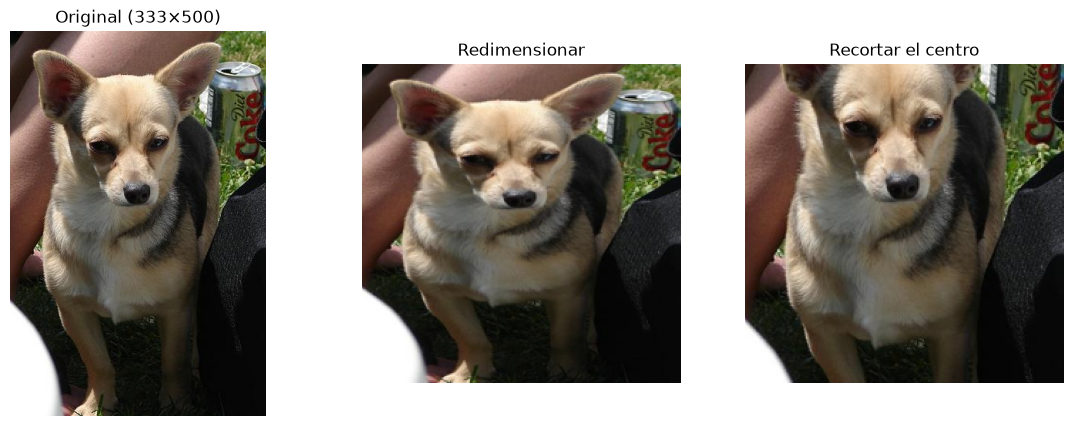

In [40]:
from PIL import ImageOps

IMG_SIZE = 224

original = Image.open(rutas[0])

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (titulo, im) in zip(axes, [
        (f"Original ({original.width}×{original.height})", original),
        ("Redimensionar", original.resize((IMG_SIZE, IMG_SIZE))),
        ("Recortar el centro", ImageOps.fit(original, (IMG_SIZE, IMG_SIZE)))]):
    ax.imshow(im)
    ax.set_title(titulo)
    ax.axis("off")
plt.show()

COMPLETAR

Para aplicar este preprocesamiento a todo el conjunto de datos creamos una función reutilizable, `cargar_dataset`, que:

1. Descarga el dataset desde Kaggle con `kagglehub`.
2. Procesa cada imagen según dos opciones:
   * **`redimensionar`**: lleva la imagen a 224x224.
   * **`recortar_centro`**: recorta la zona central cuadrada antes de redimensionar a 244x244, para no deformarla.
3. Guarda las imágenes procesadas en una carpeta nueva. Si ya existen, no se vuelven a procesar.
4. Devuelve una tabla con la ruta de cada imagen, su raza y una etiqueta numérica (de 0 a 119), junto con la lista de clases.

In [41]:
import pandas as pd
from PIL import ImageOps

def cargar_dataset(nombre="jessicali9530/stanford-dogs-dataset",
                   redimensionar=True, recortar_centro=True, img_size=224):
    path = kagglehub.dataset_download(nombre)
    rutas = sorted(glob(os.path.join(path, "images", "Images", "*", "*.jpg")))

    if redimensionar or recortar_centro:
        carpeta_salida = f"stanford_dogs_redim{int(redimensionar)}_recorte{int(recortar_centro)}"
        nuevas_rutas = []
        for ruta in rutas:
            destino = os.path.join(carpeta_salida, os.path.basename(os.path.dirname(ruta)),
                                   os.path.basename(ruta))
            if not os.path.exists(destino):
                os.makedirs(os.path.dirname(destino), exist_ok=True)
                img = Image.open(ruta).convert("RGB")
                if redimensionar and recortar_centro:
                    img = ImageOps.fit(img, (img_size, img_size))       # recorta y redimensiona
                elif redimensionar:
                    img = img.resize((img_size, img_size))              # redimensiona (deforma)
                else:
                    lado = min(img.size)
                    img = ImageOps.fit(img, (lado, lado))               # solo recorta a cuadrado
                img.save(destino)
            nuevas_rutas.append(destino)
    else:
        nuevas_rutas = rutas                                            # imágenes originales

    df = pd.DataFrame({"ruta": nuevas_rutas, "raza": [nombre_raza(r) for r in rutas]})
    clases = sorted(df["raza"].unique())
    df["etiqueta"] = df["raza"].map({c: i for i, c in enumerate(clases)})

    print(f"Imágenes: {len(df)} | Clases: {len(clases)} | "
          f"Redimensionar: {redimensionar} | Recortar centro: {recortar_centro}")
    return df, clases

In [42]:
df, clases = cargar_dataset()                                            # recortar + redimensionar (la elegida)
df, clases = cargar_dataset(recortar_centro=False)                       # solo redimensionar (deforma)
df, clases = cargar_dataset(redimensionar=False, recortar_centro=False)  # originales, sin tocar

Imágenes: 20580 | Clases: 120 | Redimensionar: True | Recortar centro: True
Imágenes: 20580 | Clases: 120 | Redimensionar: True | Recortar centro: False
Imágenes: 20580 | Clases: 120 | Redimensionar: False | Recortar centro: False


### 3.2. División en entrenamiento, validación y test

Dividimos los datos en 70 % entrenamiento, 15 % validación (para tomar decisiones durante la experimentación) y 15 % test (solo para la evaluación final, con datos no vistos durante el entrenamiento). Para división se aplica estratificación y así mantener la proporción de cada raza en los tres conjuntos, y usa una semilla fija para que las dos estrategias trabajen exactamente con los mismos datos.

In [35]:
from sklearn.model_selection import train_test_split

# Primero separamos el 15 % para test
train_df, test_df = train_test_split(df, test_size=0.15,
                                     stratify=df["etiqueta"], random_state=SEED)

# Del resto, separamos otro 15 % del total para validación
train_df, val_df = train_test_split(train_df, test_size=0.15 / 0.85,
                                    stratify=train_df["etiqueta"], random_state=SEED)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 14406 | Val: 3087 | Test: 3087


## 5. Estrategia 2: redes preentrenadas (*transfer learning* y *fine-tuning*)

En esta estrategia partimos de redes ya entrenadas en ImageNet y las adaptamos a nuestras 120 razas. Lo hacemos en dos fases:

1. **Extracción de características**: congelamos la base convolucional y entrenamos solo un clasificador nuevo encima. Es rápido, así que lo usamos para comparar varias arquitecturas.
2. **Fine-tuning**: con la arquitectura que mejor funcione, descongelamos las últimas capas de la base y las reentrenamos con una tasa de aprendizaje baja.

Hay que tener en cuenta lo que vimos en las anotaciones: Stanford Dogs se construyó a partir de ImageNet. Las redes preentrenadas ya conocen estas razas y probablemente han visto parte de estas mismas fotos, así que sus resultados serán más optimistas que los que obtendríamos con un dataset nuevo. Lo retomamos en la comparación final.

### 5.1. Carga de los datos

Usamos los conjuntos de entrenamiento, validación y test de la sección 3.2, de forma que esta estrategia se evalúa sobre exactamente las mismas imágenes que la Estrategia 1.

Las imágenes se leen con `tf.data`: cada una se recorta a su cuadrado central y se redimensiona a 224x224, igual que en `cargar_dataset` (si la imagen ya viene procesada, estas operaciones no la cambian). Los píxeles se dejan en el rango 0-255, porque cada red preentrenada espera una normalización distinta y la aplicamos dentro del modelo con su función `preprocess_input`. Las imágenes ya decodificadas se guardan en memoria con `cache()` para no volver a leerlas del disco en cada época.

In [ ]:
import time
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)

NUM_CLASES = len(clases)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def leer_imagen(ruta, etiqueta):
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    alto, ancho = tf.shape(img)[0], tf.shape(img)[1]
    lado = tf.minimum(alto, ancho)
    img = tf.image.crop_to_bounding_box(img, (alto - lado) // 2, (ancho - lado) // 2, lado, lado)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bicubic")
    # Se guarda como uint8 para que la caché ocupe 4 veces menos que en float32
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), etiqueta


def crear_dataset(df, barajar=False):
    ds = tf.data.Dataset.from_tensor_slices((df["ruta"].values, df["etiqueta"].values))
    ds = ds.map(leer_imagen, num_parallel_calls=AUTOTUNE).cache()
    if barajar:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y))
    return ds.prefetch(AUTOTUNE)


train_ds = crear_dataset(train_df, barajar=True)
val_ds = crear_dataset(val_df)
test_ds = crear_dataset(test_df)

imagenes, etiquetas = next(iter(val_ds))
print("Lote:", imagenes.shape, imagenes.dtype, "| Rango de píxeles:",
      float(tf.reduce_min(imagenes)), "-", float(tf.reduce_max(imagenes)))

Definimos también una función para dibujar las curvas de entrenamiento, que usaremos en todos los experimentos de esta sección.

In [ ]:
def graficar_curvas(historiales, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for nombre, h in historiales.items():
        epocas = range(1, len(h["loss"]) + 1)
        for ax, metrica in zip(axes, ["loss", "accuracy"]):
            linea, = ax.plot(epocas, h[f"val_{metrica}"], label=f"{nombre} (val)")
            ax.plot(epocas, h[metrica], linestyle="--", color=linea.get_color(),
                    alpha=0.6, label=f"{nombre} (train)")
    axes[0].set_title("Pérdida")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

### 5.2. Extracción de características: comparación de arquitecturas

Comparamos tres redes preentrenadas en ImageNet de diseño y tamaño muy distintos:

* **ResNet50**: red residual clásica, con unos 23,6 millones de parámetros en la base.
* **EfficientNetB0**: escala de forma equilibrada la profundidad, la anchura y la resolución; unos 4 millones.
* **MobileNetV2**: pensada para dispositivos con pocos recursos; unos 2,3 millones.

Mientras la base está congelada, su salida para una imagen no cambia de una época a otra. Por eso pasamos cada imagen por la base una sola vez, guardamos su vector de características (la salida tras el `GlobalAveragePooling`) y entrenamos el clasificador directamente sobre esos vectores. El resultado es el mismo que entrenar el modelo completo con la base congelada y sin data augmentation, pero en una fracción del tiempo, y así comparamos las tres redes en igualdad de condiciones.

El clasificador es el mismo para las tres: un `Dropout(0.3)` y una capa `Dense` de 120 neuronas con softmax. Además de la accuracy medimos la *top-5 accuracy* (la raza correcta está entre las 5 más probables), útil en un problema con tantas clases parecidas.

In [ ]:
BASES = {
    "ResNet50": (keras.applications.ResNet50, keras.applications.resnet.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    "MobileNetV2": (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
}


def crear_base(nombre):
    constructor, preprocesado = BASES[nombre]
    base = constructor(include_top=False, weights="imagenet",
                       input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    return base, preprocesado


def extraer_caracteristicas(base, preprocesado, conjuntos):
    paso = tf.function(lambda x: base(preprocesado(x), training=False))
    return {nombre: _extraer(paso, ds) for nombre, ds in conjuntos.items()}


def _extraer(paso, ds):
    X, y = [], []
    for imagenes, etiquetas in ds:
        X.append(paso(imagenes).numpy())
        y.append(etiquetas.numpy())
    return np.concatenate(X), np.concatenate(y)


def crear_clasificador(dimension):
    return keras.Sequential([
        layers.Input(shape=(dimension,)),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="clasificador")


def metricas():
    return ["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")]

In [ ]:
caracteristicas, clasificadores, historiales_fe, filas = {}, {}, {}, []

for nombre in BASES:
    base, preprocesado = crear_base(nombre)

    inicio = time.time()
    caracteristicas[nombre] = extraer_caracteristicas(
        base, preprocesado, {"train": train_ds, "val": val_ds, "test": test_ds})
    tiempo_extraccion = time.time() - inicio
    (X_tr, y_tr), (X_va, y_va) = caracteristicas[nombre]["train"], caracteristicas[nombre]["val"]

    clasificador = crear_clasificador(X_tr.shape[1])
    clasificador.compile(optimizer=keras.optimizers.Adam(1e-3),
                         loss="sparse_categorical_crossentropy", metrics=metricas())
    historia = clasificador.fit(
        X_tr, y_tr, validation_data=(X_va, y_va), epochs=60, batch_size=64, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                 restore_best_weights=True)])

    _, val_acc, val_top5 = clasificador.evaluate(X_va, y_va, verbose=0)
    clasificadores[nombre] = clasificador
    historiales_fe[nombre] = historia.history
    filas.append({
        "Modelo": nombre,
        "Parámetros base (M)": round(base.count_params() / 1e6, 1),
        "Dimensión características": X_tr.shape[1],
        "Tiempo extracción (s)": round(tiempo_extraccion),
        "Épocas": len(historia.history["loss"]),
        "Accuracy train": round(max(historia.history["accuracy"]), 4),
        "Accuracy val": round(val_acc, 4),
        "Top-5 val": round(val_top5, 4),
    })
    print(f"{nombre}: accuracy val {val_acc:.4f} | top-5 val {val_top5:.4f}")
    del base

resultados_fe = pd.DataFrame(filas).set_index("Modelo")
resultados_fe

In [ ]:
graficar_curvas(historiales_fe, "Extracción de características: clasificador sobre cada base congelada")

COMPLETAR

### 5.3. Fine-tuning

Con la base congelada la red solo puede recombinar características aprendidas para ImageNet. En el fine-tuning dejamos que las últimas capas de la base también se ajusten a las diferencias entre razas. Seguimos el procedimiento habitual:

1. **Partimos del clasificador ya entrenado** en el apartado anterior. Con un clasificador inicializado al azar, los gradientes de las primeras épocas serían grandes y estropearían los pesos preentrenados.
2. **Descongelamos solo el último bloque de la base.** Las primeras capas detectan patrones genéricos (bordes, texturas) que sirven tal cual, mientras que las últimas codifican características más ligadas a las clases de ImageNet.
3. **Usamos una tasa de aprendizaje baja (1e-5)**, para ajustar los pesos sin alejarlos demasiado de los originales.
4. **Mantenemos las capas de `BatchNormalization` congeladas y en modo inferencia** (`training=False`). Sus estadísticas se calcularon sobre ImageNet y recalcularlas con lotes de 32 imágenes desestabiliza el entrenamiento.

Como ahora sí entrenamos sobre las imágenes, añadimos data augmentation (volteo horizontal, rotación y zoom ligeros) para frenar el sobreajuste, que será mayor al haber más parámetros entrenables. Usamos transformaciones suaves porque las proporciones y la postura del perro son información útil para distinguir razas.

In [ ]:
PRIMERA_CAPA_ENTRENABLE = {
    "ResNet50": "conv5_block1_1_conv",
    "EfficientNetB0": "block6a_expand_conv",
    "MobileNetV2": "block_13_expand",
}

mejor_base = resultados_fe["Accuracy val"].idxmax()
print("Base elegida:", mejor_base)

aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

base, preprocesado = crear_base(mejor_base)
entrada = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = aumento(entrada)
x = layers.Lambda(preprocesado, name="preprocesado")(x)
x = base(x, training=False)
salida = clasificadores[mejor_base](x)
modelo_ft = keras.Model(entrada, salida, name=f"{mejor_base}_finetuning")

# Comprobación: con la base aún congelada debe dar lo mismo que el clasificador del apartado 5.2
modelo_ft.compile(loss="sparse_categorical_crossentropy", metrics=metricas())
_, acc_inicial, _ = modelo_ft.evaluate(val_ds, verbose=0)
print(f"Accuracy val antes del fine-tuning: {acc_inicial:.4f}")

base.trainable = True
indice = [capa.name for capa in base.layers].index(PRIMERA_CAPA_ENTRENABLE[mejor_base])
for i, capa in enumerate(base.layers):
    capa.trainable = i >= indice and not isinstance(capa, layers.BatchNormalization)

entrenables = sum(capa.trainable for capa in base.layers)
print(f"Capas de la base entrenables: {entrenables} de {len(base.layers)}")
modelo_ft.summary(show_trainable=True)

In [ ]:
modelo_ft.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=metricas())

inicio = time.time()
historia_ft = modelo_ft.fit(
    train_ds, validation_data=val_ds, epochs=20,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                             restore_best_weights=True)])
print(f"Tiempo de entrenamiento: {(time.time() - inicio) / 60:.1f} min")

In [ ]:
graficar_curvas({f"{mejor_base} fine-tuning": historia_ft.history},
                f"Fine-tuning de {mejor_base}")

COMPLETAR

### 5.4. Evaluación en test

Evaluamos sobre el conjunto de test, que no se ha usado en ningún momento para entrenar ni para tomar decisiones. Comparamos el modelo final con el que teníamos antes del fine-tuning para medir cuánto aporta.

In [ ]:
X_te, y_te = caracteristicas[mejor_base]["test"]
_, test_acc_fe, test_top5_fe = clasificadores[mejor_base].evaluate(X_te, y_te, verbose=0)
_, test_acc_ft, test_top5_ft = modelo_ft.evaluate(test_ds, verbose=0)

resultados_test = pd.DataFrame({
    "Accuracy test": [test_acc_fe, test_acc_ft],
    "Top-5 test": [test_top5_fe, test_top5_ft],
}, index=[f"{mejor_base} (extracción de características)", f"{mejor_base} (fine-tuning)"]).round(4)
resultados_test

Para ver dónde se equivoca el modelo, calculamos el F1 de cada raza y los pares de razas que más se confunden. Con 120 clases la matriz de confusión completa no se puede leer, así que mostramos solo las confusiones más frecuentes.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_prob = modelo_ft.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
y_real = test_df["etiqueta"].values

informe = pd.DataFrame(classification_report(y_real, y_pred, target_names=clases,
                                             output_dict=True, zero_division=0)).T
por_raza = informe.loc[clases, ["precision", "recall", "f1-score", "support"]]
print("Razas con peor F1:")
display(por_raza.sort_values("f1-score").head(10).round(3))

matriz = confusion_matrix(y_real, y_pred)
np.fill_diagonal(matriz, 0)
pares = [(clases[i], clases[j], matriz[i, j]) for i, j in zip(*np.unravel_index(
    np.argsort(matriz, axis=None)[::-1][:10], matriz.shape))]
pd.DataFrame(pares, columns=["Raza real", "Predicha como", "Imágenes"])

In [ ]:
errores = np.where(y_pred != y_real)[0]
muestra = np.random.default_rng(SEED).choice(errores, 12, replace=False)
mostrar_cuadricula(
    [test_df["ruta"].iloc[i] for i in muestra],
    [f"Real: {clases[y_real[i]]}\nPredicha: {clases[y_pred[i]]}" for i in muestra],
    "Ejemplos de errores del modelo en test")

COMPLETAR

### 5.5. Conclusiones de la Estrategia 2

COMPLETAR